# ParFlow Short Course: Overland Flow
## Tilted V domain setup

This script sets up a tilted-v Domain as shown below. It doesn't run the domain or set the slopes it just sets up the dimulation and writes out the `.pfidb` file to be used in later runs. 

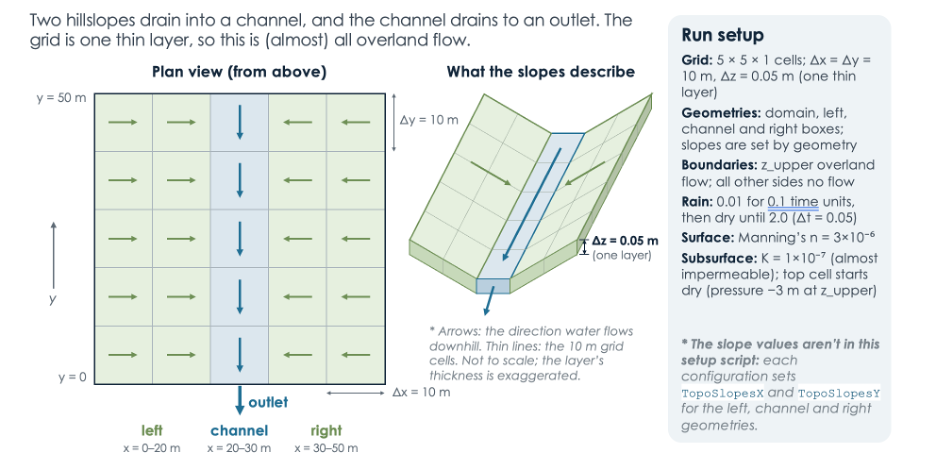



In [2]:
#-----------------------------------------------------------------------------
#running different configurations of tilted V
#-----------------------------------------------------------------------------

import os
import sys
from parflow import Run
from parflow.tools.fs import mkdir, get_absolute_path

overland = Run("overland_tiltedV")

pf_runname = "overland_tiltedV"
#base = os.path.join(os.getcwd(), "tiltedV_runs", pf_runname)
#mkdir(base)

#-----------------------------------------------------------------------------

overland.FileVersion = 4

overland.Process.Topology.P = 1
overland.Process.Topology.Q = 1
overland.Process.Topology.R = 1

#---------------------------------------------------------
# Computational Grid
#---------------------------------------------------------

overland.ComputationalGrid.Lower.X = 0.0
overland.ComputationalGrid.Lower.Y = 0.0
overland.ComputationalGrid.Lower.Z = 0.0

overland.ComputationalGrid.NX = 5
overland.ComputationalGrid.NY = 5
overland.ComputationalGrid.NZ = 1

overland.ComputationalGrid.DX = 10.0
overland.ComputationalGrid.DY = 10.0
overland.ComputationalGrid.DZ = .05

#---------------------------------------------------------
# The Names of the GeomInputs
#---------------------------------------------------------

overland.GeomInput.Names = 'domaininput leftinput rightinput channelinput'

overland.GeomInput.domaininput.GeomName = 'domain'
overland.GeomInput.leftinput.GeomName = 'left'
overland.GeomInput.rightinput.GeomName = 'right'
overland.GeomInput.channelinput.GeomName = 'channel'

overland.GeomInput.domaininput.InputType = 'Box'
overland.GeomInput.leftinput.InputType = 'Box'
overland.GeomInput.rightinput.InputType = 'Box'
overland.GeomInput.channelinput.InputType = 'Box'

#---------------------------------------------------------
# Domain Geometry
#---------------------------------------------------------

overland.Geom.domain.Lower.X = 0.0
overland.Geom.domain.Lower.Y = 0.0
overland.Geom.domain.Lower.Z = 0.0

overland.Geom.domain.Upper.X = 50.0
overland.Geom.domain.Upper.Y = 50.0
overland.Geom.domain.Upper.Z = 0.05
overland.Geom.domain.Patches = 'x_lower x_upper y_lower y_upper z_lower z_upper'

#---------------------------------------------------------
# Left Slope Geometry
#---------------------------------------------------------

overland.Geom.left.Lower.X = 0.0
overland.Geom.left.Lower.Y = 0.0
overland.Geom.left.Lower.Z = 0.0

overland.Geom.left.Upper.X = 20.0
overland.Geom.left.Upper.Y = 50.0
overland.Geom.left.Upper.Z = 0.05

#---------------------------------------------------------
# Right Slope Geometry
#---------------------------------------------------------

overland.Geom.right.Lower.X = 30.0
overland.Geom.right.Lower.Y = 0.0
overland.Geom.right.Lower.Z = 0.0

overland.Geom.right.Upper.X = 50.0
overland.Geom.right.Upper.Y = 50.0
overland.Geom.right.Upper.Z = 0.05

#---------------------------------------------------------
# Channel Geometry
#---------------------------------------------------------

overland.Geom.channel.Lower.X = 20.0
overland.Geom.channel.Lower.Y = 0.0
overland.Geom.channel.Lower.Z = 0.0

overland.Geom.channel.Upper.X = 30.0
overland.Geom.channel.Upper.Y = 50.0
overland.Geom.channel.Upper.Z = 0.05

#-----------------------------------------------------------------------------
# Perm
#-----------------------------------------------------------------------------

overland.Geom.Perm.Names = 'domain'
overland.Geom.domain.Perm.Type = 'Constant'
overland.Geom.domain.Perm.Value = 0.0000001

overland.Perm.TensorType = 'TensorByGeom'

overland.Geom.Perm.TensorByGeom.Names = 'domain'

overland.Geom.domain.Perm.TensorValX = 1.0
overland.Geom.domain.Perm.TensorValY = 1.0
overland.Geom.domain.Perm.TensorValZ = 1.0

#-----------------------------------------------------------------------------
# Specific Storage
#-----------------------------------------------------------------------------

overland.SpecificStorage.Type = 'Constant'
overland.SpecificStorage.GeomNames = 'domain'
overland.Geom.domain.SpecificStorage.Value = 1.0e-4

#-----------------------------------------------------------------------------
# Phases
#-----------------------------------------------------------------------------

overland.Phase.Names = 'water'

overland.Phase.water.Density.Type = 'Constant'
overland.Phase.water.Density.Value = 1.0

overland.Phase.water.Viscosity.Type = 'Constant'
overland.Phase.water.Viscosity.Value = 1.0

#-----------------------------------------------------------------------------
# Contaminants
#-----------------------------------------------------------------------------

overland.Contaminants.Names = ''

#-----------------------------------------------------------------------------
# Retardation
#-----------------------------------------------------------------------------

overland.Geom.Retardation.GeomNames = ''

#-----------------------------------------------------------------------------
# Gravity
#-----------------------------------------------------------------------------

overland.Gravity = 1.0

#-----------------------------------------------------------------------------
# Setup timing info
#-----------------------------------------------------------------------------
overland.TimingInfo.BaseUnit = 0.05
overland.TimingInfo.StartCount = 0
overland.TimingInfo.StartTime = 0.0
overland.TimingInfo.StopTime = 2.0
overland.TimingInfo.DumpInterval = -1
overland.TimeStep.Type = 'Constant'
overland.TimeStep.Value = 0.05

#-----------------------------------------------------------------------------
# Porosity
#-----------------------------------------------------------------------------

overland.Geom.Porosity.GeomNames = 'domain'
overland.Geom.domain.Porosity.Type = 'Constant'
overland.Geom.domain.Porosity.Value = 0.01

#-----------------------------------------------------------------------------
# Domain
#-----------------------------------------------------------------------------

overland.Domain.GeomName = 'domain'

#-----------------------------------------------------------------------------
# Relative Permeability
#-----------------------------------------------------------------------------

overland.Phase.RelPerm.Type = 'VanGenuchten'
overland.Phase.RelPerm.GeomNames = 'domain'

overland.Geom.domain.RelPerm.Alpha = 6.0
overland.Geom.domain.RelPerm.N = 2.

#---------------------------------------------------------
# Saturation
#---------------------------------------------------------

overland.Phase.Saturation.Type = 'VanGenuchten'
overland.Phase.Saturation.GeomNames = 'domain'

overland.Geom.domain.Saturation.Alpha = 6.0
overland.Geom.domain.Saturation.N = 2.
overland.Geom.domain.Saturation.SRes = 0.2
overland.Geom.domain.Saturation.SSat = 1.0

#-----------------------------------------------------------------------------
# Wells
#-----------------------------------------------------------------------------

overland.Wells.Names = ''

#-----------------------------------------------------------------------------
# Time Cycles
#-----------------------------------------------------------------------------

overland.Cycle.Names = 'constant rainrec'
overland.Cycle.constant.Names = 'alltime'
overland.Cycle.constant.alltime.Length = 1
overland.Cycle.constant.Repeat = -1

# rainfall and recession time periods are defined here
# rain for 1 hour, recession for 2 hours

overland.Cycle.rainrec.Names = 'rain rec'
overland.Cycle.rainrec.rain.Length = 2
overland.Cycle.rainrec.rec.Length = 300
overland.Cycle.rainrec.Repeat = -1

#-----------------------------------------------------------------------------
# Boundary Conditions: Pressure
#-----------------------------------------------------------------------------

overland.BCPressure.PatchNames = overland.Geom.domain.Patches

overland.Patch.x_lower.BCPressure.Type = 'FluxConst'
overland.Patch.x_lower.BCPressure.Cycle = 'constant'
overland.Patch.x_lower.BCPressure.alltime.Value = 0.0

overland.Patch.y_lower.BCPressure.Type = 'FluxConst'
overland.Patch.y_lower.BCPressure.Cycle = 'constant'
overland.Patch.y_lower.BCPressure.alltime.Value = 0.0

overland.Patch.z_lower.BCPressure.Type = 'FluxConst'
overland.Patch.z_lower.BCPressure.Cycle = 'constant'
overland.Patch.z_lower.BCPressure.alltime.Value = 0.0

overland.Patch.x_upper.BCPressure.Type = 'FluxConst'
overland.Patch.x_upper.BCPressure.Cycle = 'constant'
overland.Patch.x_upper.BCPressure.alltime.Value = 0.0

overland.Patch.y_upper.BCPressure.Type = 'FluxConst'
overland.Patch.y_upper.BCPressure.Cycle = 'constant'
overland.Patch.y_upper.BCPressure.alltime.Value = 0.0

## overland flow boundary condition with very heavy rainfall
overland.Patch.z_upper.BCPressure.Type = 'OverlandFlow'
overland.Patch.z_upper.BCPressure.Cycle = 'rainrec'
overland.Patch.z_upper.BCPressure.rain.Value = -0.01
overland.Patch.z_upper.BCPressure.rec.Value = 0.0000

#---------------------------------------------------------
# Mannings coefficient
#---------------------------------------------------------

overland.Mannings.Type = 'Constant'
overland.Mannings.GeomNames = 'domain'
overland.Mannings.Geom.domain.Value = 3.e-6

#-----------------------------------------------------------------------------
# Phase sources:
#-----------------------------------------------------------------------------

overland.PhaseSources.water.Type = 'Constant'
overland.PhaseSources.water.GeomNames = 'domain'
overland.PhaseSources.water.Geom.domain.Value = 0.0

#-----------------------------------------------------------------------------
# Exact solution specification for error calculations
#-----------------------------------------------------------------------------

overland.KnownSolution = 'NoKnownSolution'

#-----------------------------------------------------------------------------
# Set solver parameters
#-----------------------------------------------------------------------------

overland.Solver = 'Richards'
overland.Solver.MaxIter = 2500

overland.Solver.Nonlinear.MaxIter = 100
overland.Solver.Nonlinear.ResidualTol = 1e-9
overland.Solver.Nonlinear.EtaChoice = 'EtaConstant'
overland.Solver.Nonlinear.EtaValue = 0.01
overland.Solver.Nonlinear.UseJacobian = True
overland.Solver.Nonlinear.DerivativeEpsilon = 1e-15
overland.Solver.Nonlinear.StepTol = 1e-20
overland.Solver.Nonlinear.Globalization = 'LineSearch'
overland.Solver.Linear.KrylovDimension = 50
overland.Solver.Linear.MaxRestart = 2
overland.Solver.OverlandKinematic.Epsilon = 1E-5

overland.Solver.Linear.Preconditioner = 'PFMG'
overland.Solver.Linear.Preconditioner.PCMatrixType = 'PFSymmetric'
overland.Solver.PrintSubsurf = False
overland.Solver.Drop = 1E-20
overland.Solver.AbsTol = 1E-10

overland.Solver.WriteSiloSubsurfData = False
overland.Solver.WriteSiloPressure = False
overland.Solver.WriteSiloSlopes = False

overland.Solver.WriteSiloSaturation = False
overland.Solver.WriteSiloConcentration = False

overland.Solver.PrintMannings = True
overland.Solver.PrintSlopes = True

#---------------------------------------------------------
# Initial conditions: water pressure
#---------------------------------------------------------

# set water table to be at the bottom of the domain, the top layer is initially dry
overland.ICPressure.Type = 'HydroStaticPatch'
overland.ICPressure.GeomNames = 'domain'
overland.Geom.domain.ICPressure.Value = -3.0

overland.Geom.domain.ICPressure.RefGeom = 'domain'
overland.Geom.domain.ICPressure.RefPatch = 'z_upper'

# Write out to pfidb
#print(f"Writing run files to: {base}")
#overland.write(working_directory=base)

print("Writing run files to current directory")
overland.write()

Writing run files to current directory


('/workspaces/ParFlow_CUAHSI_VU/my_work/overland_tiltedV.pfidb',
 '/workspaces/ParFlow_CUAHSI_VU/my_work/overland_tiltedV')